# Итоговое сравнение лабораторных работ 1–5

Ноутбук сопоставляет результаты KNN, линейных моделей, дерева решений, случайного леса и градиентного бустинга для классификации Digits и регрессии `load_diabetes`. Он использует данные, которые автоматически формируются в конце `laboratories_1_5.ipynb`.

**Порядок запуска:** сначала выполните основной ноутбук целиком, затем этот файл. Если папка `results/` ещё не создана, вернитесь к основному ноутбуку и запустите его сверху вниз.


In [1]:
# Проверяем наличие результатов и загружаем таблицы, созданные основным ноутбуком.
from pathlib import Path
import pandas as pd

RESULTS = Path('results')
required = ['metrics.csv','baseline_vs_tuned.csv','custom_vs_baseline.csv','custom_improved_vs_tuned.csv','audit.json']
missing = [name for name in required if not (RESULTS / name).exists()]
if missing:
    raise FileNotFoundError(
        'Не найдены файлы: ' + ', '.join(missing) + '. '
        'Сначала выполните все ячейки laboratories_1_5.ipynb.'
    )

metrics = pd.read_csv(RESULTS / 'metrics.csv')
baseline_comparison = pd.read_csv(RESULTS / 'baseline_vs_tuned.csv')
custom_comparison = pd.read_csv(RESULTS / 'custom_vs_baseline.csv')
custom_improved_comparison = pd.read_csv(RESULTS / 'custom_improved_vs_tuned.csv')
import json
audit = json.loads((RESULTS / 'audit.json').read_text(encoding='utf-8'))

print('Строк метрик:', len(metrics))
print('Лабораторные:', ', '.join(sorted(metrics['lab'].unique())))
print('Стадии:', ', '.join(sorted(metrics['stage'].unique())))


Строк метрик: 44
Лабораторные: ЛР1, ЛР2, ЛР3, ЛР4, ЛР5
Стадии: baseline, baseline_scaled, custom, custom_improved, feature_engineered, improved_sklearn, tuned


## 1. Baseline против улучшенного sklearn-варианта

Reference-стадии различаются по лабораторным: ЛР1 — `improved_sklearn`, ЛР2 — `feature_engineered`, ЛР3–ЛР5 — `tuned`. Поэтому в таблице явно указано поле `reference_stage`. Для macro-F1 положительная дельта означает улучшение; для RMSE отрицательная дельта означает улучшение; для R² положительная дельта означает улучшение.


In [2]:
# Показываем baseline и соответствующую улучшенную sklearn-стадию для каждой задачи.
display(baseline_comparison)


,lab,task,reference_stage,model_baseline,model_improved,accuracy_baseline,precision_macro_baseline,recall_macro_baseline,f1_macro_baseline,MAE_baseline,...,MAE_improved,RMSE_improved,R2_improved,accuracy_delta,precision_macro_delta,recall_macro_delta,f1_macro_delta,MAE_delta,RMSE_delta,R2_delta
0,ЛР1,classification,improved_sklearn,KNN без масштабирования,KNN настроенный + стандартизация,0.983333,0.983449,0.983095,0.983046,NaN,...,NaN,NaN,NaN,-0.019444,-0.018859,-0.019374,-0.019606,NaN,NaN,NaN
1,ЛР1,regression,improved_sklearn,KNN без масштабирования,KNN настроенный + стандартизация,NaN,NaN,NaN,NaN,42.648475,...,42.781701,54.493337,0.439517,NaN,NaN,NaN,NaN,0.133226,-0.159888,0.003294
2,ЛР2,classification,feature_engineered,Логистическая регрессия,Логистическая регрессия + новые признаки,0.958333,0.958731,0.958012,0.958075,NaN,...,NaN,NaN,NaN,0.022222,0.022108,0.022385,0.022355,NaN,NaN,NaN
3,ЛР2,regression,feature_engineered,Линейная регрессия,Ridge + новые признаки,NaN,NaN,NaN,NaN,42.794095,...,42.105741,52.654356,0.476708,NaN,NaN,NaN,NaN,-0.688354,-1.199089,0.024105
4,ЛР3,classification,tuned,ЛР3 решающее дерево,ЛР3 решающее дерево настроенный,0.825000,0.823584,0.824247,0.823049,NaN,...,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
5,ЛР3,regression,tuned,ЛР3 решающее дерево,ЛР3 решающее дерево настроенный,NaN,NaN,NaN,NaN,54.528090,...,48.096592,59.604541,0.329445,NaN,NaN,NaN,NaN,-6.431498,-10.941882,0.268791
6,ЛР4,classification,tuned,ЛР4 случайный лес,ЛР4 случайный лес настроенный,0.961111,0.961970,0.960710,0.960722,NaN,...,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
7,ЛР4,regression,tuned,ЛР4 случайный лес,ЛР4 случайный лес настроенный,NaN,NaN,NaN,NaN,44.053034,...,44.231746,54.490419,0.439577,NaN,NaN,NaN,NaN,0.178713,0.158011,-0.003246
8,ЛР5,classification,tuned,ЛР5 гистограммный градиентный бустинг,ЛР5 гистограммный градиентный бустинг настроенный,0.955556,0.955918,0.955000,0.954733,NaN,...,NaN,NaN,NaN,-0.002778,-0.002327,-0.002778,-0.002493,NaN,NaN,NaN
9,ЛР5,regression,tuned,ЛР5 гистограммный градиентный бустинг,ЛР5 гистограммный градиентный бустинг настроенный,NaN,NaN,NaN,NaN,45.204033,...,43.056510,53.062205,0.468570,NaN,NaN,NaN,NaN,-2.147523,-3.967040,0.082432


## 2. Рейтинг всех проверенных алгоритмов

В рейтинге присутствуют и sklearn-модели, и самостоятельные реализации. Для классификации сортировка идёт по убыванию macro-F1; для регрессии — по возрастанию RMSE. Это рейтинг результатов на конкретном тестовом разбиении.


In [3]:
# Строим единый рейтинг всех стадий классификации по macro-F1.
classification_ranking = metrics[metrics['task']=='classification'].sort_values('f1_macro',ascending=False)
display(classification_ranking[['lab','model','implementation','stage','accuracy','precision_macro','recall_macro','f1_macro']])


,lab,model,implementation,stage,accuracy,precision_macro,recall_macro,f1_macro
0,ЛР1,KNN без масштабирования,sklearn,baseline,0.983333,0.983449,0.983095,0.983046
4,ЛР1,KNN настроенный,sklearn,tuned,0.983333,0.983449,0.983095,0.983046
8,ЛР1,MyKNN,собственная реализация,custom,0.983333,0.983449,0.983095,0.983046
14,ЛР2,Логистическая регрессия + новые признаки,sklearn,feature_engineered,0.980556,0.980839,0.980397,0.980430
18,ЛР2,Своя softmax-регрессия + новые признаки,собственная реализация,custom_improved,0.975000,0.975842,0.974916,0.975020
2,ЛР1,KNN со стандартизацией,sklearn,baseline_scaled,0.963889,0.964590,0.963722,0.963440
10,ЛР1,MyKNN улучшенный,собственная реализация,custom_improved,0.963889,0.964590,0.963722,0.963440
6,ЛР1,KNN настроенный + стандартизация,sklearn,improved_sklearn,0.963889,0.964590,0.963722,0.963440
30,ЛР4,ЛР4 случайный лес настроенный,sklearn,tuned,0.961111,0.961970,0.960710,0.960722
28,ЛР4,ЛР4 случайный лес,sklearn,baseline,0.961111,0.961970,0.960710,0.960722


In [4]:
# Строим единый рейтинг всех стадий регрессии по RMSE.
regression_ranking = metrics[metrics['task']=='regression'].sort_values('RMSE')
display(regression_ranking[['lab','model','implementation','stage','MAE','RMSE','R2']])


,lab,model,implementation,stage,MAE,RMSE,R2
19,ЛР2,Своя линейная регрессия + новые признаки,собственная реализация,custom_improved,41.170222,51.891580,0.491759
15,ЛР2,Ridge + новые признаки,sklearn,feature_engineered,42.105741,52.654356,0.476708
39,ЛР5,ЛР5 гистограммный градиентный бустинг настроенный,sklearn,tuned,43.056510,53.062205,0.468570
33,ЛР4,Своя модель случайный лес,собственная реализация,custom,42.494447,53.088426,0.468045
17,ЛР2,Своя линейная регрессия,собственная реализация,custom,42.794095,53.853446,0.452603
13,ЛР2,Линейная регрессия,sklearn,baseline,42.794095,53.853446,0.452603
29,ЛР4,ЛР4 случайный лес,sklearn,baseline,44.053034,54.332408,0.442823
31,ЛР4,ЛР4 случайный лес настроенный,sklearn,tuned,44.231746,54.490419,0.439577
11,ЛР1,MyKNN улучшенный,собственная реализация,custom_improved,42.781701,54.493337,0.439517
7,ЛР1,KNN настроенный + стандартизация,sklearn,improved_sklearn,42.781701,54.493337,0.439517


## 3. Собственные реализации: baseline-сравнение

Эта таблица отвечает на пункты задания о сравнении самостоятельной реализации с исходной sklearn-моделью. Отрицательная дельта RMSE означает, что собственная реализация ошибается меньше; положительная дельта macro-F1 означает, что собственная реализация классифицирует лучше.


In [5]:
# Сравниваем исходные собственные модели с соответствующими sklearn-baseline.
display(custom_comparison)


,lab,task,custom_model,baseline_model,accuracy_custom,precision_macro_custom,recall_macro_custom,f1_macro_custom,MAE_custom,RMSE_custom,...,MAE_baseline,RMSE_baseline,R2_baseline,accuracy_delta,precision_macro_delta,recall_macro_delta,f1_macro_delta,MAE_delta,RMSE_delta,R2_delta
0,ЛР1,classification,MyKNN,KNN без масштабирования,0.983333,0.983449,0.983095,0.983046,NaN,NaN,...,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,ЛР1,regression,MyKNN,KNN без масштабирования,NaN,NaN,NaN,NaN,42.648475,54.653225,...,42.648475,54.653225,0.436223,NaN,NaN,NaN,NaN,0.000000e+00,0.000000,0.000000
2,ЛР2,classification,Своя softmax-регрессия,Логистическая регрессия,0.958333,0.959047,0.958087,0.958137,NaN,NaN,...,NaN,NaN,NaN,0.000000,0.000316,0.000075,0.000061,NaN,NaN,NaN
3,ЛР2,regression,Своя линейная регрессия,Линейная регрессия,NaN,NaN,NaN,NaN,42.794095,53.853446,...,42.794095,53.853446,0.452603,NaN,NaN,NaN,NaN,2.131628e-14,0.000000,0.000000
4,ЛР3,classification,Своя модель решающее дерево,ЛР3 решающее дерево,0.844444,0.848408,0.844314,0.841860,NaN,NaN,...,NaN,NaN,NaN,0.019444,0.024824,0.020066,0.018811,NaN,NaN,NaN
5,ЛР3,regression,Своя модель решающее дерево,ЛР3 решающее дерево,NaN,NaN,NaN,NaN,47.267142,59.069458,...,54.528090,70.546423,0.060654,NaN,NaN,NaN,NaN,-7.260948e+00,-11.476964,0.280777
6,ЛР4,classification,Своя модель случайный лес,ЛР4 случайный лес,0.863889,0.865138,0.863604,0.862041,NaN,NaN,...,NaN,NaN,NaN,-0.097222,-0.096833,-0.097106,-0.098681,NaN,NaN,NaN
7,ЛР4,regression,Своя модель случайный лес,ЛР4 случайный лес,NaN,NaN,NaN,NaN,42.494447,53.088426,...,44.053034,54.332408,0.442823,NaN,NaN,NaN,NaN,-1.558587e+00,-1.243983,0.025222
8,ЛР5,classification,Своя модель градиентный бустинг,ЛР5 гистограммный градиентный бустинг,0.827778,0.831849,0.827104,0.825678,NaN,NaN,...,NaN,NaN,NaN,-0.127778,-0.124069,-0.127896,-0.129055,NaN,NaN,NaN
9,ЛР5,regression,Своя модель градиентный бустинг,ЛР5 гистограммный градиентный бустинг,NaN,NaN,NaN,NaN,46.170385,55.265639,...,45.204033,57.029245,0.386138,NaN,NaN,NaN,NaN,9.663520e-01,-1.763606,0.037380


## 4. Собственные улучшенные модели против улучшенного sklearn

Техники из пункта 3 перенесены в самостоятельные реализации и результаты сопоставлены с улучшенным sklearn-вариантом. В `reference_stage` указана точная стадия сравнения: ЛР1 — масштабированный KNN с выбранным k; ЛР2 — feature engineering; ЛР3–ЛР5 — tuned-модель.


In [6]:
# Показываем результаты custom_improved и дельты относительно соответствующего sklearn-эталона.
display(custom_improved_comparison)


,lab,task,reference_stage,improved_custom_model,reference_sklearn_model,accuracy_custom_improved,precision_macro_custom_improved,recall_macro_custom_improved,f1_macro_custom_improved,MAE_custom_improved,...,MAE_reference_sklearn,RMSE_reference_sklearn,R2_reference_sklearn,accuracy_delta,precision_macro_delta,recall_macro_delta,f1_macro_delta,MAE_delta,RMSE_delta,R2_delta
0,ЛР1,classification,improved_sklearn,MyKNN улучшенный,KNN настроенный + стандартизация,0.963889,0.964590,0.963722,0.963440,NaN,...,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,ЛР1,regression,improved_sklearn,MyKNN улучшенный,KNN настроенный + стандартизация,NaN,NaN,NaN,NaN,42.781701,...,42.781701,54.493337,0.439517,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000
2,ЛР2,classification,feature_engineered,Своя softmax-регрессия + новые признаки,Логистическая регрессия + новые признаки,0.975000,0.975842,0.974916,0.975020,NaN,...,NaN,NaN,NaN,-0.005556,-0.004998,-0.005480,-0.005411,NaN,NaN,NaN
3,ЛР2,regression,feature_engineered,Своя линейная регрессия + новые признаки,Ridge + новые признаки,NaN,NaN,NaN,NaN,41.170222,...,42.105741,52.654356,0.476708,NaN,NaN,NaN,NaN,-0.935519,-0.762776,0.015052
4,ЛР3,classification,tuned,Своя модель дерево + параметры CV,ЛР3 решающее дерево настроенный,0.763889,0.765827,0.763419,0.762739,NaN,...,NaN,NaN,NaN,-0.061111,-0.057756,-0.060828,-0.060311,NaN,NaN,NaN
5,ЛР3,regression,tuned,Своя модель дерево + параметры CV,ЛР3 решающее дерево настроенный,NaN,NaN,NaN,NaN,47.793953,...,48.096592,59.604541,0.329445,NaN,NaN,NaN,NaN,-0.302639,1.170328,-0.026591
6,ЛР4,classification,tuned,Своя модель лес + параметры CV,ЛР4 случайный лес настроенный,0.958333,0.960252,0.958091,0.958152,NaN,...,NaN,NaN,NaN,-0.002778,-0.001718,-0.002619,-0.002570,NaN,NaN,NaN
7,ЛР4,regression,tuned,Своя модель лес + параметры CV,ЛР4 случайный лес настроенный,NaN,NaN,NaN,NaN,43.947628,...,44.231746,54.490419,0.439577,NaN,NaN,NaN,NaN,-0.284118,0.387737,-0.008004
8,ЛР5,classification,tuned,Своя модель бустинг + параметры CV,ЛР5 гистограммный градиентный бустинг настроенный,0.875000,0.879888,0.874260,0.873458,NaN,...,NaN,NaN,NaN,-0.077778,-0.073703,-0.077962,-0.078782,NaN,NaN,NaN
9,ЛР5,regression,tuned,Своя модель бустинг + параметры CV,ЛР5 гистограммный градиентный бустинг настроенный,NaN,NaN,NaN,NaN,51.448420,...,43.056510,53.062205,0.468570,NaN,NaN,NaN,NaN,8.391910,6.336564,-0.134503


## 5. Автоматическая сводка результатов

Следующая ячейка отдельно показывает лидеров среди sklearn-моделей и среди самостоятельных реализаций. Такое разделение важно: наиболее удачная самостоятельная реализация не должна незаметно подменять собой ответ на вопрос о лучшей модели sklearn, и наоборот.


In [7]:
# Находим лучшие модели по каждой задаче отдельно для sklearn и собственных реализаций.
reference_stages = ['baseline','tuned','feature_engineered','improved_sklearn']
sklearn_models = metrics[(metrics['implementation']=='sklearn') & metrics['stage'].isin(reference_stages)]
custom_models = metrics[metrics['implementation']=='собственная реализация']

best_sklearn_classifier = sklearn_models[sklearn_models['task']=='classification'].sort_values('f1_macro',ascending=False).iloc[0]
best_custom_classifier = custom_models[custom_models['task']=='classification'].sort_values('f1_macro',ascending=False).iloc[0]
best_sklearn_regressor = sklearn_models[sklearn_models['task']=='regression'].sort_values('RMSE').iloc[0]
best_custom_regressor = custom_models[custom_models['task']=='regression'].sort_values('RMSE').iloc[0]

summary = pd.DataFrame([
    {'category':'sklearn / classification','lab':best_sklearn_classifier['lab'],'model':best_sklearn_classifier['model'],'stage':best_sklearn_classifier['stage'],'macro_F1':best_sklearn_classifier['f1_macro'],'RMSE':None,'R2':None},
    {'category':'custom / classification','lab':best_custom_classifier['lab'],'model':best_custom_classifier['model'],'stage':best_custom_classifier['stage'],'macro_F1':best_custom_classifier['f1_macro'],'RMSE':None,'R2':None},
    {'category':'sklearn / regression','lab':best_sklearn_regressor['lab'],'model':best_sklearn_regressor['model'],'stage':best_sklearn_regressor['stage'],'macro_F1':None,'RMSE':best_sklearn_regressor['RMSE'],'R2':best_sklearn_regressor['R2']},
    {'category':'custom / regression','lab':best_custom_regressor['lab'],'model':best_custom_regressor['model'],'stage':best_custom_regressor['stage'],'macro_F1':None,'RMSE':best_custom_regressor['RMSE'],'R2':best_custom_regressor['R2']},
])
display(summary)


,category,lab,model,stage,macro_F1,RMSE,R2
0,sklearn / classification,ЛР1,KNN без масштабирования,baseline,0.983046,NaN,NaN
1,custom / classification,ЛР1,MyKNN,custom,0.983046,NaN,NaN
2,sklearn / regression,ЛР2,Ridge + новые признаки,feature_engineered,NaN,52.654356,0.476708
3,custom / regression,ЛР2,Своя линейная регрессия + новые признаки,custom_improved,NaN,51.891580,0.491759


## 6. Проверка гипотез и аудит

Аудит отражает правило принятия решения: улучшение считается подтверждённым только при улучшении целевой метрики на отложенной выборке. В частности, настройка параметров может не дать прироста и даже ухудшить часть результатов.


In [8]:
# Выводим машиночитаемые результаты проверки H1–H4.
display(pd.json_normalize(audit['hypotheses'],sep='.').T.rename(columns={0:'result'}))
print('Ограничения эксперимента:')
for limitation in audit['limitations']:
    print('-',limitation)


,result
H1_scaling.classification_supported,False
H1_scaling.regression_supported,True
H1_scaling.classification_f1_delta,-0.019606
H1_scaling.regression_rmse_delta,-0.159888
H2_feature_engineering.classification_supported,True
H2_feature_engineering.regression_supported,True
H2_feature_engineering.classification_f1_delta,0.022355
H2_feature_engineering.regression_rmse_delta,-1.199089
H3_tuning.ЛР3.classification.supported,False
H3_tuning.ЛР3.classification.baseline,0.823049


Ограничения эксперимента:
- Все выводы основаны на одном фиксированном train/test-разбиении.
- Собственные CART/ансамбли — компактные учебные реализации с ограниченным поиском разбиений.


## 7. Диагностические графики

Графики создаются основным ноутбуком: распределение классов, матрица ошибок лучшего классификатора, фактические и предсказанные значения лучшего регрессора, кривая сходимости собственной softmax-регрессии и важности признаков случайного леса.


class_distribution.png


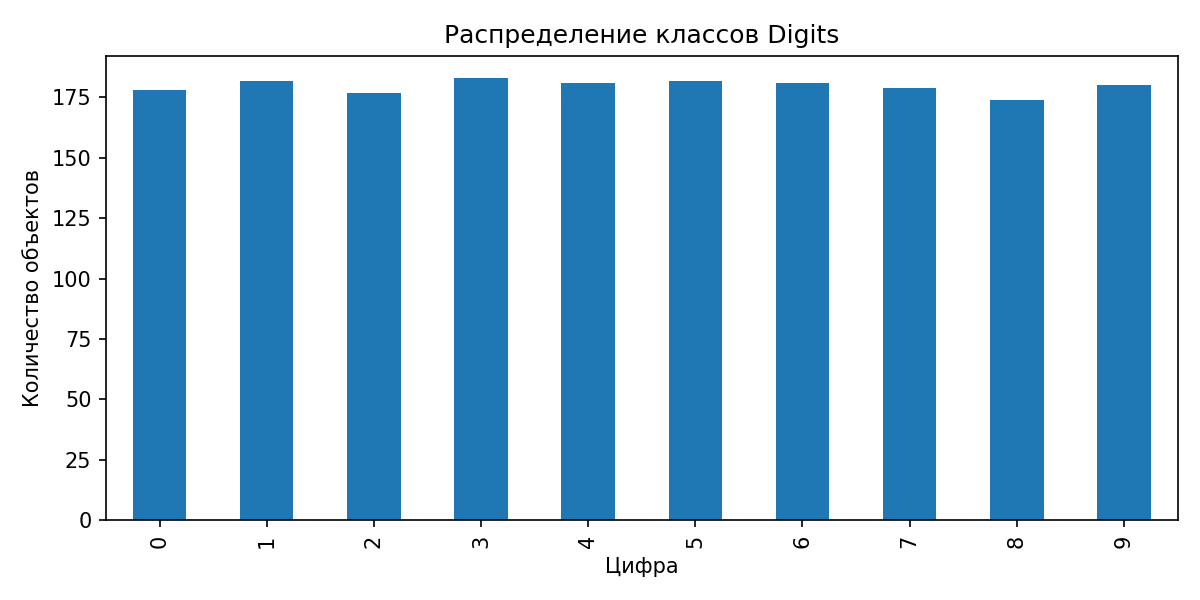

best_classifier_confusion_matrix.png


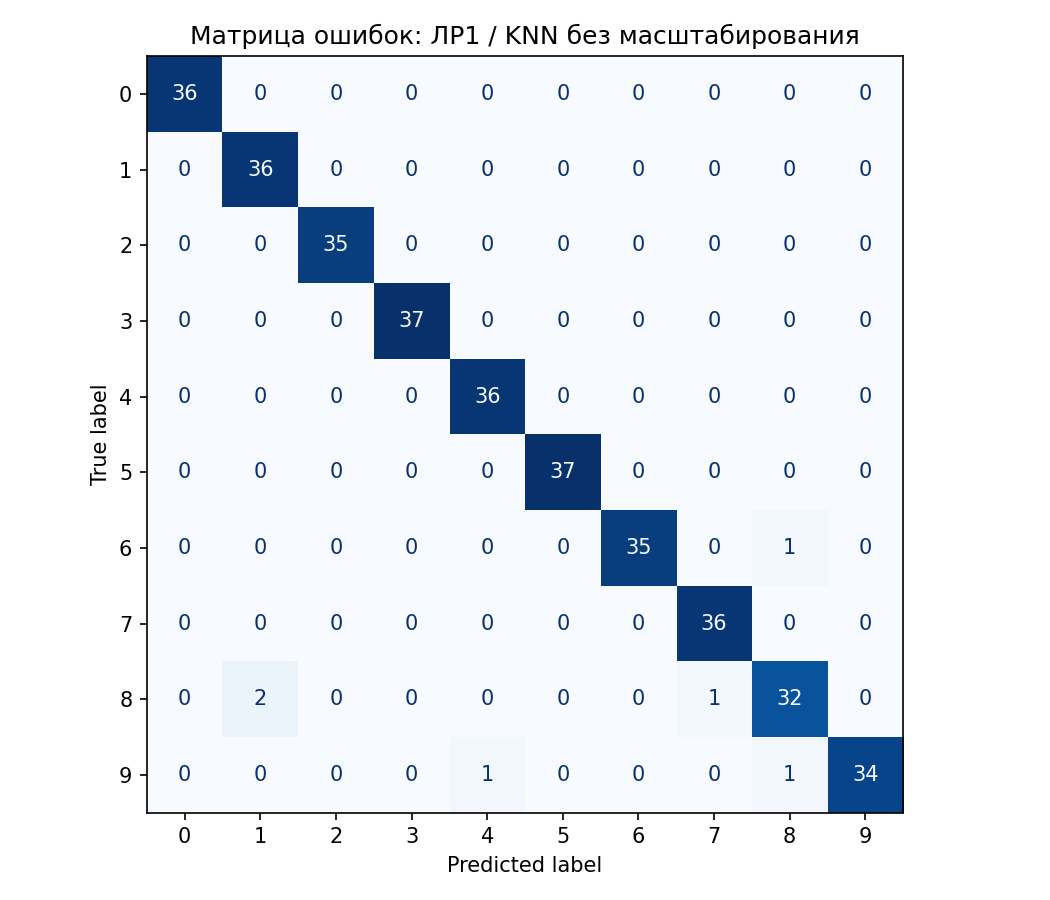

best_regressor_actual_vs_predicted.png


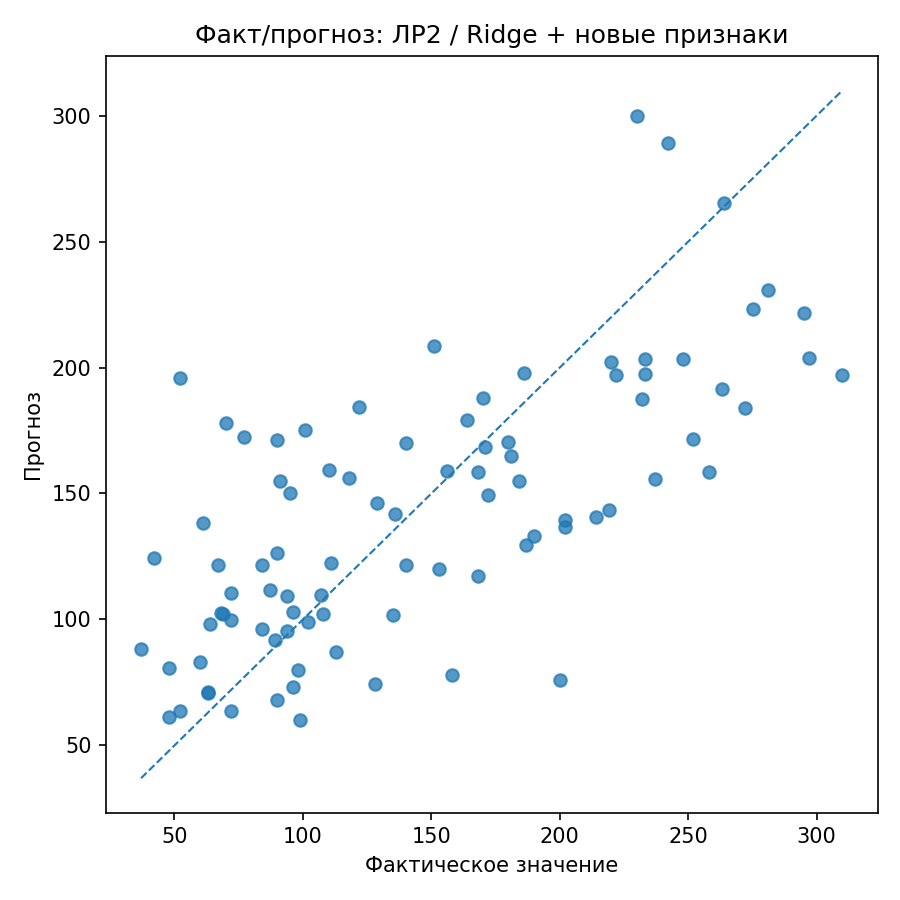

softmax_loss.png


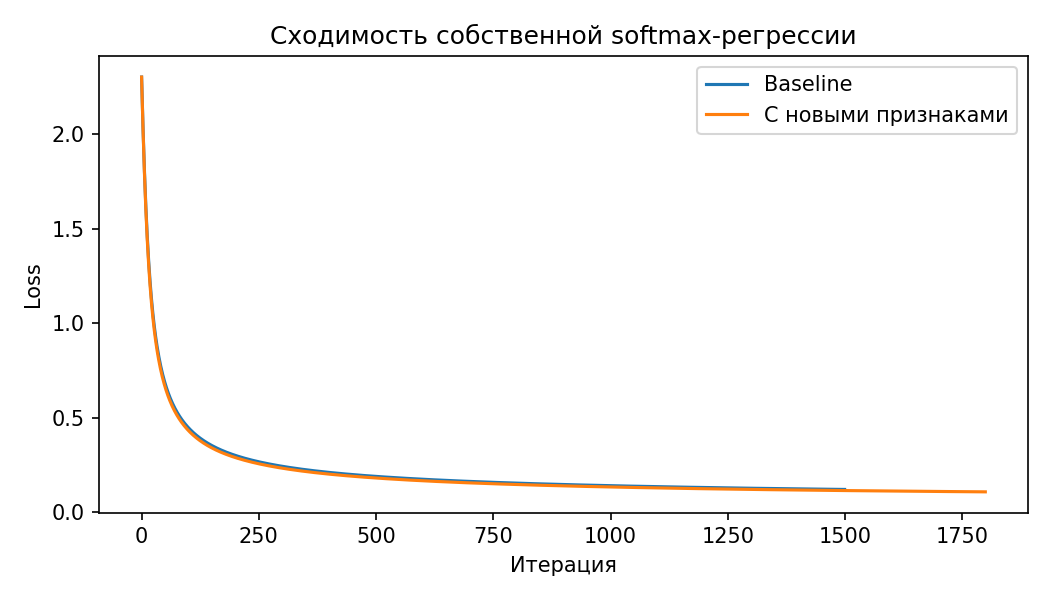

random_forest_feature_importance_digits.png


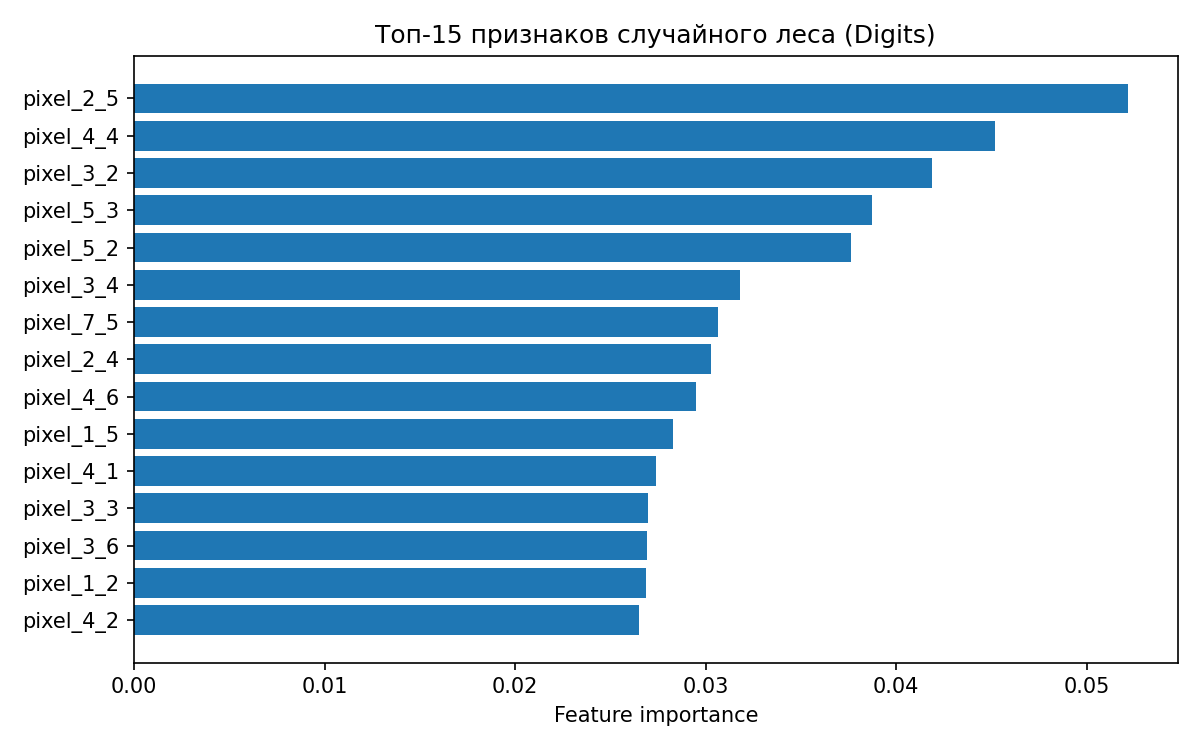

In [9]:
# Показываем созданные основным ноутбуком диагностические изображения, если они доступны.
from IPython.display import Image, display
figure_files = [
    'class_distribution.png',
    'best_classifier_confusion_matrix.png',
    'best_regressor_actual_vs_predicted.png',
    'softmax_loss.png',
    'random_forest_feature_importance_digits.png',
]
for filename in figure_files:
    path = RESULTS / 'figures' / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print('Нет файла:', path)


## 8. Итоговая интерпретация

Качество следует интерпретировать отдельно для классификации и регрессии. Среди sklearn-моделей в текущем эксперименте лидер классификации определяется максимальным macro-F1, а лидер регрессии — минимальным RMSE. Собственные реализации оцениваются дополнительно: они демонстрируют работу алгоритмов, но их компактные ограничения могут менять результат при переносе гиперпараметров.

Все выводы относятся к одному разбиению с фиксированным `random_state`.
